기준연월,부두,선박수,실제재항시간합계,보정재항시간합계,실제평균재항시간,보정평균재항시간
2022-01,1부두,71,2069.42,2147.37,29.15,30.24
2022-01,2부두,143,3286.38,3548.63,22.98,24.82
2022-01,3부두,75,2195.82,2442.73,29.28,32.57
2022-01,4부두,53,1625.68,1828.76,30.67,34.50
2022-01,5부두,77,2438.12,2632.01,31.66,34.18
2022-02,1부두,57,1850.63,1836.72,32.47,32.22
2022-02,2부두,133,3219.02,3720.83,24.20,27.98
2022-02,3부두,72,1983.42,2359.87,27.55,32.78
2022-02,4부두,47,1647.50,1837.77,35.05,39.10
2022-02,5부두,62,2782.07,3078.82,44.87,49.66


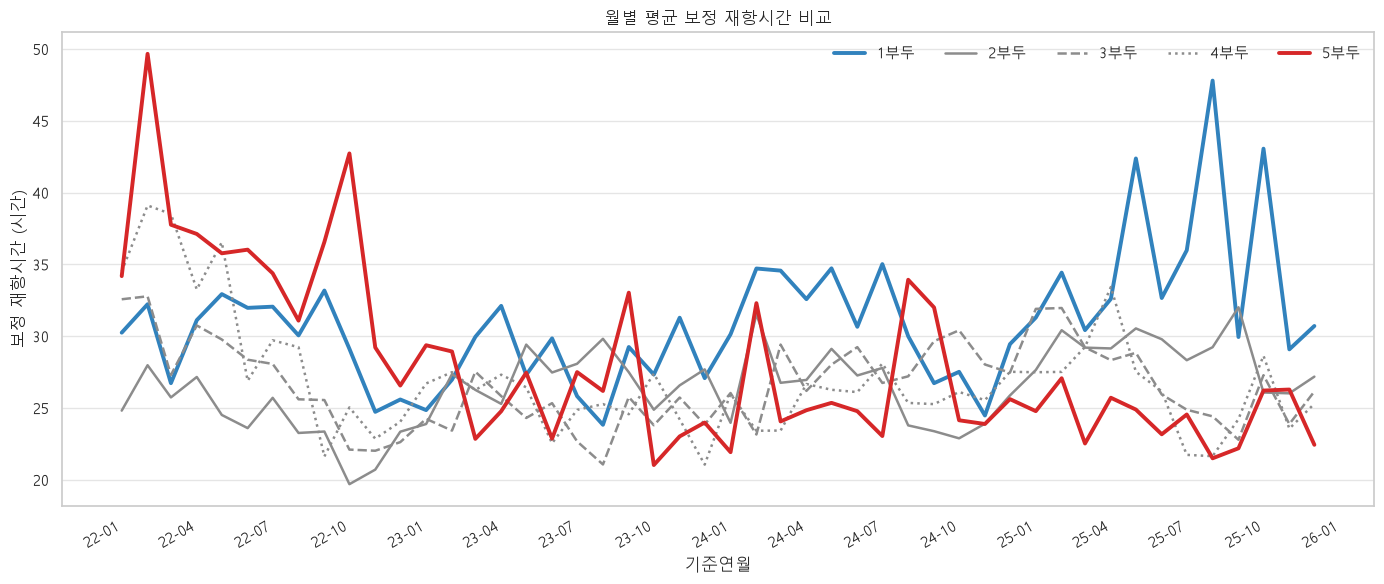

In [2]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = Path("C:/final")

DATA_PATH = PROJECT_ROOT / "data" / "record.csv"
record = pd.read_csv(DATA_PATH, encoding="utf-8-sig")

piers = ["1부두", "2부두", "3부두", "4부두", "5부두"]
기준총톤수 = 74739
보정지수 = 0.244

record["입항일시"] = pd.to_datetime(record["입항일시"])
record["총톤수"] = pd.to_numeric(
    record["총톤수"].astype(str).str.replace(",", "", regex=False),
    errors="coerce",
)
record["재항시간"] = pd.to_numeric(record["재항시간"], errors="coerce")
record["부두"] = record["계선장소"].str.extract(
    r"([1-5])부두", expand=False
).map(lambda pier: f"{pier}부두" if pd.notna(pier) else pd.NA)
record["기준연월"] = record["입항일시"].dt.to_period("M").dt.to_timestamp()

# 보정 재항시간 = 실제 재항시간 × (74,739 ÷ 총톤수)^0.244
valid = (
    record["부두"].isin(piers)
    & record["총톤수"].gt(0)
    & record["재항시간"].notna()
)
record = record.loc[valid].copy()
record["보정계수"] = (기준총톤수 / record["총톤수"]) ** 보정지수
record["보정재항시간"] = record["재항시간"] * record["보정계수"]

월별_보정재항시간 = (
    record.groupby(["기준연월", "부두"], as_index=False)
    .agg(
        선박수=("재항시간", "count"),
        실제재항시간합계=("재항시간", "sum"),
        보정재항시간합계=("보정재항시간", "sum"),
        실제평균재항시간=("재항시간", "mean"),
        보정평균재항시간=("보정재항시간", "mean"),
    )
    .sort_values(["기준연월", "부두"])
)

목록 = 월별_보정재항시간.copy()
목록["기준연월"] = 목록["기준연월"].dt.strftime("%Y-%m")
display(목록.style.format(precision=2).hide(axis="index"))

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

fig, ax = plt.subplots(figsize=(14, 6))
colors = {
    "1부두": "#3182bd",
    "2부두": "#8c8c8c",
    "3부두": "#8c8c8c",
    "4부두": "#8c8c8c",
    "5부두": "#d62728",
}
linestyles = {
    "1부두": "-",
    "2부두": "-",
    "3부두": "--",
    "4부두": ":",
    "5부두": "-",
}

for pier in piers:
    pier_data = 월별_보정재항시간[월별_보정재항시간["부두"] == pier]
    ax.plot(
        pier_data["기준연월"],
        pier_data["보정평균재항시간"],
        label=pier,
        color=colors[pier],
        linestyle=linestyles[pier],
        linewidth=2.8 if pier in ["1부두", "5부두"] else 1.8,
    )

ax.set_title("월별 평균 보정 재항시간 비교")
ax.set_xlabel("기준연월")
ax.set_ylabel("보정 재항시간 (시간)")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%y-%m"))
ax.grid(axis="x", visible=False)
ax.legend(ncol=5, frameon=False)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()
